In [278]:

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import joblib


df = pd.read_csv(r'D:\churn-prediction-system\Customer_Churn.csv')


print(df.shape)
df.head()

(10000, 21)


,CustomerID,Age,Gender,City,TotalPurchases,AveragePurchaseValue,TotalSpend,MonthlySpend,SessionsPerMonth,AvgSessionDurationMinutes,...,SupportTickets,DeviceUsed,HasPremiumMembership,LastInteractionDaysAgo,Tenure,ContractType,SatisfactionScore,UsageFrequency,Complaints,Churn
0,ce743892-17ee-4549-9b74-d5a735e80946,57,Male,North Erinfort,8,164.03,1435.03,239.17,8,15.2,...,1,Mobile,0,122,7,Month-to-Month,2,8,2,1
1,5242176a-f013-4db0-ba7f-9acfa0c99811,51,Female,Donnabury,23,236.72,4845.66,210.68,29,17.2,...,5,Tablet,1,90,34,One Year,6,10,2,0
2,2b575902-975d-4cf6-a620-2cbb54d22360,49,Female,Nathanshire,23,208.06,4880.59,375.43,11,11.2,...,2,Mobile,0,151,25,One Year,9,30,0,0
3,27ad8adb-d1f0-4ee3-b27b-4e5201a1e723,65,Female,West Emily,20,158.03,2749.56,88.70,11,40.0,...,0,Desktop,1,64,41,One Year,8,29,0,0
4,13bc1446-4547-4608-9514-3febda897aec,26,Female,New Gerald,11,244.48,2416.89,75.53,17,55.1,...,2,Tablet,0,168,44,Two Year,8,27,0,0


In [279]:
df.isnull().sum()

CustomerID                   0
Age                          0
Gender                       0
City                         0
TotalPurchases               0
AveragePurchaseValue         0
TotalSpend                   0
MonthlySpend                 0
SessionsPerMonth             0
AvgSessionDurationMinutes    0
PagesViewedPerSession        0
SupportTickets               0
DeviceUsed                   0
HasPremiumMembership         0
LastInteractionDaysAgo       0
Tenure                       0
ContractType                 0
SatisfactionScore            0
UsageFrequency               0
Complaints                   0
Churn                        0
dtype: int64

In [280]:
print(df.shape)
print(df.info())

(10000, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 10000 non-null  object 
 1   Age                        10000 non-null  int64  
 2   Gender                     10000 non-null  object 
 3   City                       10000 non-null  object 
 4   TotalPurchases             10000 non-null  int64  
 5   AveragePurchaseValue       10000 non-null  float64
 6   TotalSpend                 10000 non-null  float64
 7   MonthlySpend               10000 non-null  float64
 8   SessionsPerMonth           10000 non-null  int64  
 9   AvgSessionDurationMinutes  10000 non-null  float64
 10  PagesViewedPerSession      10000 non-null  int64  
 11  SupportTickets             10000 non-null  int64  
 12  DeviceUsed                 10000 non-null  object 
 13  HasPremiumMembership       10000 no

In [281]:
df.drop('CustomerID', axis=1, inplace=True)

In [282]:
df.drop('City', axis=1, inplace=True)

In [283]:
df.head()

,Age,Gender,TotalPurchases,AveragePurchaseValue,TotalSpend,MonthlySpend,SessionsPerMonth,AvgSessionDurationMinutes,PagesViewedPerSession,SupportTickets,DeviceUsed,HasPremiumMembership,LastInteractionDaysAgo,Tenure,ContractType,SatisfactionScore,UsageFrequency,Complaints,Churn
0,57,Male,8,164.03,1435.03,239.17,8,15.2,13,1,Mobile,0,122,7,Month-to-Month,2,8,2,1
1,51,Female,23,236.72,4845.66,210.68,29,17.2,20,5,Tablet,1,90,34,One Year,6,10,2,0
2,49,Female,23,208.06,4880.59,375.43,11,11.2,6,2,Mobile,0,151,25,One Year,9,30,0,0
3,65,Female,20,158.03,2749.56,88.70,11,40.0,16,0,Desktop,1,64,41,One Year,8,29,0,0
4,26,Female,11,244.48,2416.89,75.53,17,55.1,11,2,Tablet,0,168,44,Two Year,8,27,0,0


In [284]:
num_cols = df.select_dtypes(include=['number'])

print(num_cols.head())

   Age  TotalPurchases  AveragePurchaseValue  TotalSpend  MonthlySpend  \
0   57               8                164.03     1435.03        239.17   
1   51              23                236.72     4845.66        210.68   
2   49              23                208.06     4880.59        375.43   
3   65              20                158.03     2749.56         88.70   
4   26              11                244.48     2416.89         75.53   

   SessionsPerMonth  AvgSessionDurationMinutes  PagesViewedPerSession  \
0                 8                       15.2                     13   
1                29                       17.2                     20   
2                11                       11.2                      6   
3                11                       40.0                     16   
4                17                       55.1                     11   

   SupportTickets  HasPremiumMembership  LastInteractionDaysAgo  Tenure  \
0               1                     0  

In [285]:
outlier_counts = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    outlier_counts[col] = len(outliers)

print(pd.DataFrame.from_dict(
    outlier_counts,
    orient='index',
    columns=['Outlier_Count']
).sort_values('Outlier_Count', ascending=False))

                           Outlier_Count
TotalSpend                           605
MonthlySpend                         165
TotalPurchases                       150
Complaints                           111
AveragePurchaseValue                   0
SessionsPerMonth                       0
AvgSessionDurationMinutes              0
Age                                    0
PagesViewedPerSession                  0
SupportTickets                         0
LastInteractionDaysAgo                 0
HasPremiumMembership                   0
Tenure                                 0
SatisfactionScore                      0
UsageFrequency                         0
Churn                                  0


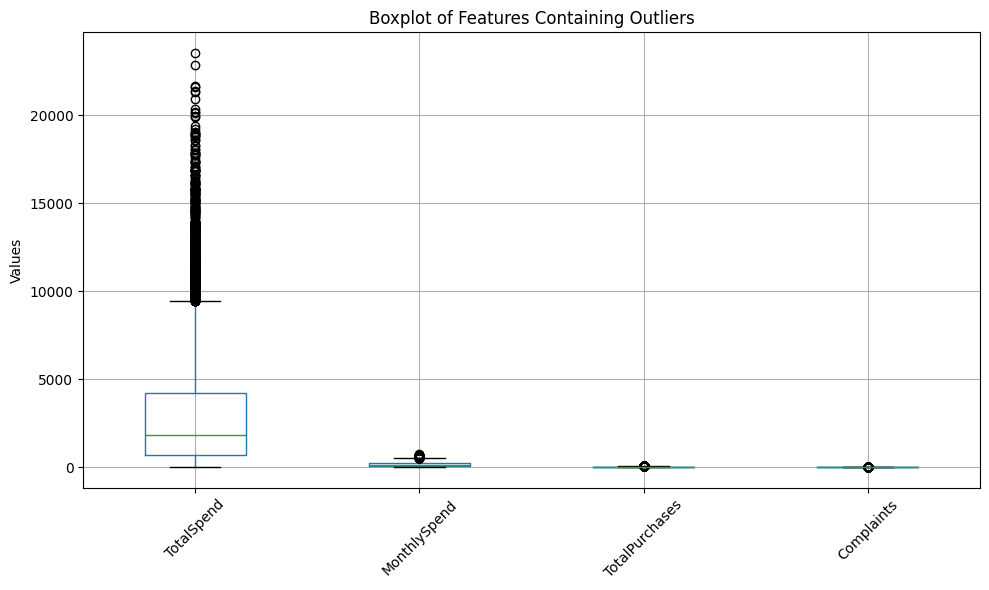

In [286]:


outlier_cols = ['TotalSpend', 'MonthlySpend', 'TotalPurchases', 'Complaints']

plt.figure(figsize=(10, 6))
df[outlier_cols].boxplot()

plt.title('Boxplot of Features Containing Outliers')
plt.ylabel('Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [287]:
cols = [
    'TotalSpend',
    'MonthlySpend',
    'TotalPurchases',
    'Complaints'
]

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

In [288]:


df['TotalSpend'] = np.log1p(df['TotalSpend'])
df['MonthlySpend'] = np.log1p(df['MonthlySpend'])
df['TotalPurchases'] = np.log1p(df['TotalPurchases'])

In [289]:
df.head()

,Age,Gender,TotalPurchases,AveragePurchaseValue,TotalSpend,MonthlySpend,SessionsPerMonth,AvgSessionDurationMinutes,PagesViewedPerSession,SupportTickets,DeviceUsed,HasPremiumMembership,LastInteractionDaysAgo,Tenure,ContractType,SatisfactionScore,UsageFrequency,Complaints,Churn
0,57,Male,2.197225,164.03,7.269638,5.481347,8,15.2,13,1,Mobile,0,122,7,Month-to-Month,2,8,2.0,1
1,51,Female,3.178054,236.72,8.486045,5.355076,29,17.2,20,5,Tablet,1,90,34,One Year,6,10,2.0,0
2,49,Female,3.178054,208.06,8.493226,5.930732,11,11.2,6,2,Mobile,0,151,25,One Year,9,30,0.0,0
3,65,Female,3.044522,158.03,7.919560,4.496471,11,40.0,16,0,Desktop,1,64,41,One Year,8,29,0.0,0
4,26,Female,2.484907,244.48,7.790651,4.337683,17,55.1,11,2,Tablet,0,168,44,Two Year,8,27,0.0,0


In [290]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [291]:
X = pd.get_dummies(
    X,
    columns=['Gender', 'DeviceUsed', 'ContractType'],
    drop_first=True
)

In [292]:
print(y.value_counts())
print(y.value_counts(normalize=True) * 100)

Churn
0    7387
1    2613
Name: count, dtype: int64
Churn
0    73.87
1    26.13
Name: proportion, dtype: float64


In [293]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [294]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [295]:
smote = SMOTE(random_state=42)

X_train, y_train = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())

Churn
0    5910
1    5910
Name: count, dtype: int64


In [296]:
lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)[:,1]



rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:,1]


xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)
xgb_prob = xgb.predict_proba(X_test)[:,1]

In [297]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    'Precision': [
        precision_score(y_test, lr_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, xgb_pred)
    ],
    'Recall': [
        recall_score(y_test, lr_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, xgb_pred)
    ],
    'F1 Score': [
        f1_score(y_test, lr_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, xgb_pred)
    ],
    'ROC AUC': [
        roc_auc_score(y_test, lr_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, xgb_prob)
    ]
})

print(results.sort_values('ROC AUC', ascending=False))

                 Model  Accuracy  Precision  Recall  F1 Score   ROC AUC
0  Logistic Regression    0.9990   0.996190     1.0  0.998092  0.999997
2              XGBoost    0.9995   0.998092     1.0  0.999045  0.999994
1        Random Forest    0.9995   0.998092     1.0  0.999045  0.999992


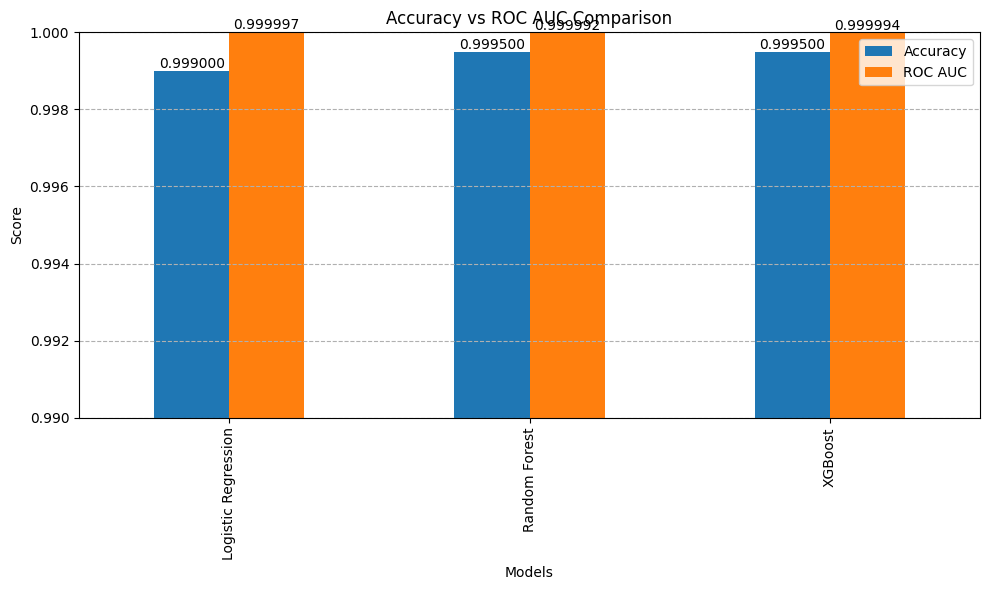

In [ ]:


comparison = results[['Model', 'Accuracy', 'ROC AUC']]
comparison = comparison.set_index('Model')

ax = comparison.plot(kind='bar', figsize=(10, 6))

plt.title('Accuracy vs ROC AUC Comparison')
plt.xlabel('Models')
plt.ylabel('Score')

# Zoom in near 1.0 if values are very close
plt.ylim(0.99, 1.0)

for container in ax.containers:
    ax.bar_label(container, fmt='%.6f')

plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()

In [299]:
best_model = results.loc[results['ROC AUC'].idxmax()]

print("Best Model:")
print(best_model)

Best Model:
Model        Logistic Regression
Accuracy                   0.999
Precision                0.99619
Recall                       1.0
F1 Score                0.998092
ROC AUC                 0.999997
Name: 0, dtype: object


In [300]:
print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1477
           1       1.00      1.00      1.00       523

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [301]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb.feature_importances_
})

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
)

print(feature_importance.head(10))

                   Feature  Importance
13          UsageFrequency    0.800863
12       SatisfactionScore    0.157311
11                  Tenure    0.032937
1           TotalPurchases    0.001701
10  LastInteractionDaysAgo    0.001356
9     HasPremiumMembership    0.001292
14              Complaints    0.001154
5         SessionsPerMonth    0.000941
2     AveragePurchaseValue    0.000539
8           SupportTickets    0.000509


Confusion Matrix:
[[1476    1]
 [   0  523]]


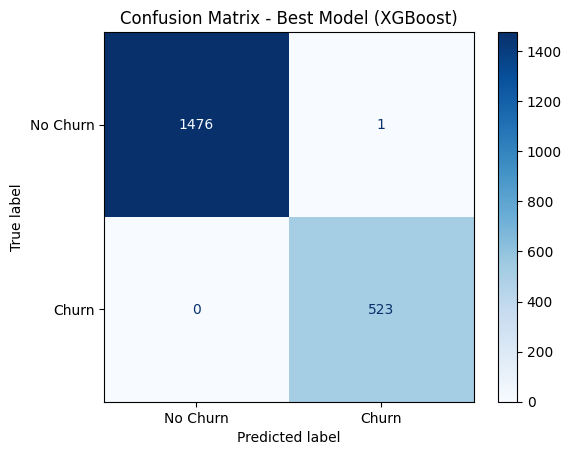

In [302]:



# Predictions from best model
xgb_pred = xgb.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, xgb_pred)

print("Confusion Matrix:")
print(cm)

# Plot
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Best Model (XGBoost)')
plt.show()


In [303]:
# Training accuracy
train_pred = xgb.predict(X_train)
train_acc = accuracy_score(y_train, train_pred)

# Testing accuracy
test_pred = xgb.predict(X_test)
test_acc = accuracy_score(y_test, test_pred)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)

Training Accuracy: 1.0
Testing Accuracy: 0.9995


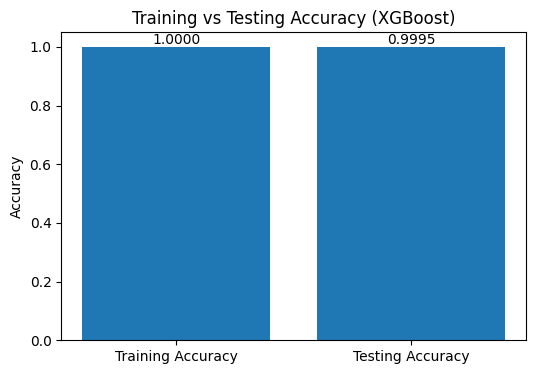

In [304]:


accuracies = [train_acc, test_acc]
labels = ['Training Accuracy', 'Testing Accuracy']

plt.figure(figsize=(6, 4))
plt.bar(labels, accuracies)

plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.title('Training vs Testing Accuracy (XGBoost)')

for i, v in enumerate(accuracies):
    plt.text(i, v + 0.01, f'{v:.4f}', ha='center')

plt.show()

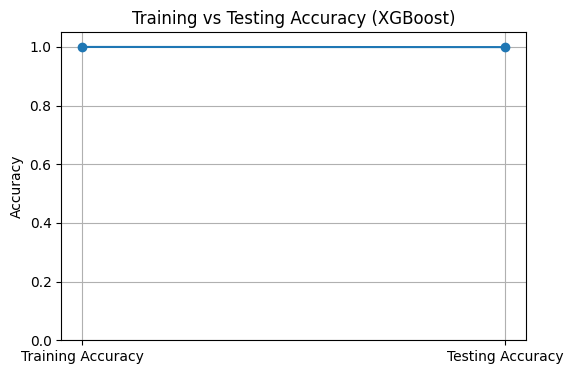

In [305]:


plt.figure(figsize=(6,4))
plt.plot(
    ['Training Accuracy', 'Testing Accuracy'],
    [train_acc, test_acc],
    marker='o'
)

plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.title('Training vs Testing Accuracy (XGBoost)')
plt.grid(True)

plt.show()

In [306]:
joblib.dump(xgb, 'best_xgboost_model.pkl')

print("Model saved successfully")
joblib.dump(scaler, 'scaler.pkl')

print("Scaler saved successfully")

feature_names = X.columns.tolist()

joblib.dump(feature_names, 'feature_names.pkl')

Model saved successfully
Scaler saved successfully


['feature_names.pkl']